# SPY vs QQQ: Quantitative ETF Comparison

## Project overview

This notebook presents a quantitative comparison of two widely traded US equity exchange-traded funds (ETFs):

- **SPY** tracks the S&P 500 Index and provides exposure to large-cap US equities.
- **QQQ** tracks the Nasdaq-100 Index and provides exposure to large non-financial companies listed on the Nasdaq, with substantial growth and technology-sector representation.

The analysis compares their historical returns, cumulative growth, volatility, drawdowns and risk-adjusted performance.

**Research question:** Over the five-year sample, did QQQ's higher average daily return come with greater risk, and which ETF delivered the stronger risk-adjusted performance?

**Data source:** Yahoo Finance, accessed through `yfinance`  
**Observation period:** 22 November 2021 to 20 November 2026  
**Frequency:** Daily  
**Price adjustment:** `auto_adjust=True`

The notebook uses adjusted OHLCV data and calculates returns from adjusted closing prices. The saved outputs represent the data retrieved in the recorded run; Yahoo Finance data may change when the notebook is re-run.

> **Disclaimer:** This is a historical, educational analysis and is not investment advice. Past performance does not predict future results.


## 1. Environment and libraries

The analysis is implemented in Python. It uses:

- **pandas** and **NumPy** for data manipulation and numerical calculations;
- **yfinance** to retrieve historical market data;
- **Matplotlib** and **Plotly** for visualisation.

The following cells check the Python environment and import the libraries required for the analysis.


In [1]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: w:\python_projects\Quantitative projects\equity-index-quantitative-research\.venv\Scripts\python.exe
Python version: 3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)]


In [2]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import plotly.express as px

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Data collection

Daily open, high, low, close and volume (OHLCV) data are downloaded for SPY and QQQ over the most recent five-year period available from Yahoo Finance.

The download uses `auto_adjust=True`. This adjusts historical prices for distributions and stock splits, so the adjusted `Close` series is used to calculate daily returns and compare historical growth.

The saved dataset covers **22 November 2021 to 20 November 2026**. Re-running the download may produce a different date range or updated observations as new market data become available.


In [3]:
import yfinance as yf

# Define the ETFs we want to study
tickers = ["SPY", "QQQ"]

# Download five years of daily historical data
market_data = yf.download(
    tickers,
    period="5y",
    interval="1d",
    auto_adjust=True
)

# Display the first five rows
market_data.head()

[*********************100%***********************]  2 of 2 completed


Price            Close                    High                     Low  \
Ticker             QQQ         SPY         QQQ         SPY         QQQ   
Date                                                                     
2021-11-22  387.542175  437.319366  396.675091  442.903123  387.435429   
2021-11-23  385.775818  437.899292  388.444841  438.750421  381.350094   
2021-11-24  387.018097  439.068420  387.299536  439.190014  380.981250   
2021-11-26  379.680756  429.275818  385.834065  433.886853  378.292841   
2021-11-29  387.920776  434.541534  388.930161  436.374719  383.504767   

Price                         Open                Volume             
Ticker             SPY         QQQ         SPY       QQQ        SPY  
Date                                                                 
2021-11-22  437.113599  393.627567  440.424577  61715400   72762000  
2021-11-23  434.401270  386.387242  436.992047  70098700   73206500  
2021-11-24  435.093385  383.300859  435.907093  46954400   61858800  
2021-11-26  428.153443  384.446150  432.427783  51533300  112669600  
2021-11-29  431.857221  384.232683  434.045825  54447100   86268800

## 3. Data structure and initial inspection

The downloaded dataset contains **1,255 daily observations and 10 columns**: Open, High, Low, Close and Volume for each ETF.

The columns use a two-level MultiIndex, with the price field as the first level (`Price`) and the ticker as the second (`Ticker`). The inspection checks the dataset dimensions, column structure, data types and missing values before calculating performance measures.


In [4]:
# 1. Check the dimensions of the dataset
print("Dataset shape:", market_data.shape)

# 2. Check column names
print("\nColumn structure:")
print(market_data.columns)

# 3. Check data types
print("\nData types:")
print(market_data.dtypes)

# 4. Check missing values
print("\nMissing values:")
print(market_data.isnull().sum())

Dataset shape: (1255, 10)

Column structure:
MultiIndex([( 'Close', 'QQQ'),
            ( 'Close', 'SPY'),
            (  'High', 'QQQ'),
            (  'High', 'SPY'),
            (   'Low', 'QQQ'),
            (   'Low', 'SPY'),
            (  'Open', 'QQQ'),
            (  'Open', 'SPY'),
            ('Volume', 'QQQ'),
            ('Volume', 'SPY')],
           names=['Price', 'Ticker'])

Data types:
Price   Ticker
Close   QQQ       float64
        SPY       float64
High    QQQ       float64
        SPY       float64
Low     QQQ       float64
        SPY       float64
Open    QQQ       float64
        SPY       float64
Volume  QQQ         int64
        SPY         int64
dtype: object

Missing values:
Price   Ticker
Close   QQQ       0
        SPY       0
High    QQQ       0
        SPY       0
Low     QQQ       0
        SPY       0
Open    QQQ       0
        SPY       0
Volume  QQQ       0
        SPY       0
dtype: int64


### Data quality checks

The validation checks examine:

- missing values;
- duplicate dates;
- observations where High is below Low;
- Open or Close prices outside the daily Low-High range;
- negative trading volume.

**Saved output:** all five checks return zero issues for the downloaded sample. There are no missing values or duplicate dates, and no observations fail the tested price-range or volume checks.

These checks provide basic structural validation. They do not independently confirm the accuracy or completeness of the prices supplied by Yahoo Finance.


In [5]:
# 1. Check total missing values
print("Total missing values:", market_data.isnull().sum().sum())

# 2. Check duplicate dates
print("Duplicate dates:", market_data.index.duplicated().sum())

# 3. Check whether High is below Low
invalid_high_low = (
    market_data["High"] < market_data["Low"]
).sum()

print("Invalid High-Low observations:", invalid_high_low)

# 4. Check whether Open is outside the daily range
invalid_open = (
    (market_data["Open"] > market_data["High"]) |
    (market_data["Open"] < market_data["Low"])
).sum()

print("Invalid Open observations:", invalid_open)

# 5. Check whether Close is outside the daily range
invalid_close = (
    (market_data["Close"] > market_data["High"]) |
    (market_data["Close"] < market_data["Low"])
).sum()

print("Invalid Close observations:", invalid_close)

# 6. Check negative trading volume
negative_volume = (market_data["Volume"] < 0).sum()

print("Negative volume observations:", negative_volume)

Total missing values: 0
Duplicate dates: 0
Invalid High-Low observations: Ticker
QQQ    0
SPY    0
dtype: int64
Invalid Open observations: Ticker
QQQ    0
SPY    0
dtype: int64
Invalid Close observations: Ticker
QQQ    0
SPY    0
dtype: int64
Negative volume observations: Ticker
QQQ    0
SPY    0
dtype: int64


## 4. Daily returns

Daily percentage returns measure the percentage change in an ETF's adjusted closing price from one trading day to the next.

**Formula**

`Daily Return (%) = ((Current Adjusted Close / Previous Adjusted Close) - 1) × 100`

Where:

- **Current Adjusted Close** is the adjusted closing price on the current trading day.
- **Previous Adjusted Close** is the adjusted closing price on the previous trading day.

The first return is missing because there is no preceding observation for comparison. This is expected when calculating percentage changes with `pct_change()`.


In [6]:
# Extract closing prices for both ETFs
closing_prices = market_data["Close"]

# Calculate daily percentage returns
daily_returns = closing_prices.pct_change() * 100

# Display the first 10 observations
daily_returns.head(10)

Ticker,QQQ,SPY
Date,,
2021-11-22,NaN,NaN
2021-11-23,-0.455785,0.132609
2021-11-24,0.322021,0.266986
2021-11-26,-1.895865,-2.230314
2021-11-29,2.170250,1.226651
2021-11-30,-1.468652,-1.945761
2021-12-01,-1.701286,-1.110722
2021-12-02,0.720709,1.531623
2021-12-03,-1.738862,-0.870121


### Average return and volatility

The notebook calculates the arithmetic mean and standard deviation of daily percentage returns for each ETF.

Daily volatility is annualised using the conventional 252-trading-day approximation:

`Annualised Volatility = Daily Volatility × √252`

**Saved sample results**

| Metric | QQQ | SPY |
|---|---:|---:|
| Average daily return | 0.0477% | 0.0429% |
| Daily volatility | 1.4809% | 1.0985% |
| Annualised volatility | 23.5089% | 17.4388% |

**Interpretation**

QQQ had the higher average daily return in this sample. It also had higher daily and annualised volatility, meaning its daily returns fluctuated more than SPY's over the observation period.

The average daily return is a historical arithmetic mean, not a forecast or guaranteed future return. Annualised volatility is a measure of variability, not a direct measure of the maximum possible loss.


In [7]:
# Calculate average daily returns
average_returns = daily_returns.mean()

# Calculate daily volatility (standard deviation)
daily_volatility = daily_returns.std()

# Annualise volatility using 252 trading days
annual_volatility = daily_volatility * np.sqrt(252)

print("Average daily returns (%):")
print(average_returns)

print("\nDaily volatility (%):")
print(daily_volatility)

print("\nAnnualised volatility (%):")
print(annual_volatility)

Average daily returns (%):
Ticker
QQQ    0.046966
SPY    0.042387
dtype: float64

Daily volatility (%):
Ticker
QQQ    1.483438
SPY    1.100075
dtype: float64

Annualised volatility (%):
Ticker
QQQ    23.548847
SPY    17.463141
dtype: float64


## 5. Cumulative growth comparison

Cumulative growth shows how a hypothetical initial investment of **$1** would have changed in value if daily returns had been reinvested throughout the sample.

**Formula**

`Cumulative Growth = (1 + Return₁) × (1 + Return₂) × ... × (1 + Returnₜ)`

**Methodology**

- Daily percentage returns are converted to decimal returns.
- Returns are compounded sequentially.
- The first missing return is filled with zero so that the initial value remains $1.

The chart compares the resulting hypothetical growth paths for QQQ and SPY.

A higher ending cumulative-growth value indicates greater growth over this particular sample. The calculation excludes investor-specific costs such as taxes, transaction costs and bid-ask spreads, and should not be interpreted as a forecast.


In [8]:
# Calculate cumulative growth of $1
growth = (1 + daily_returns.fillna(0) / 100).cumprod()

# Display the results
print(growth.tail())

Ticker           QQQ       SPY
Date                          
2026-11-16  1.707556  1.692013
2026-11-17  1.695170  1.674840
2026-11-18  1.701776  1.669718
2026-11-19  1.664438  1.636950
2026-11-20  1.570023  1.577360


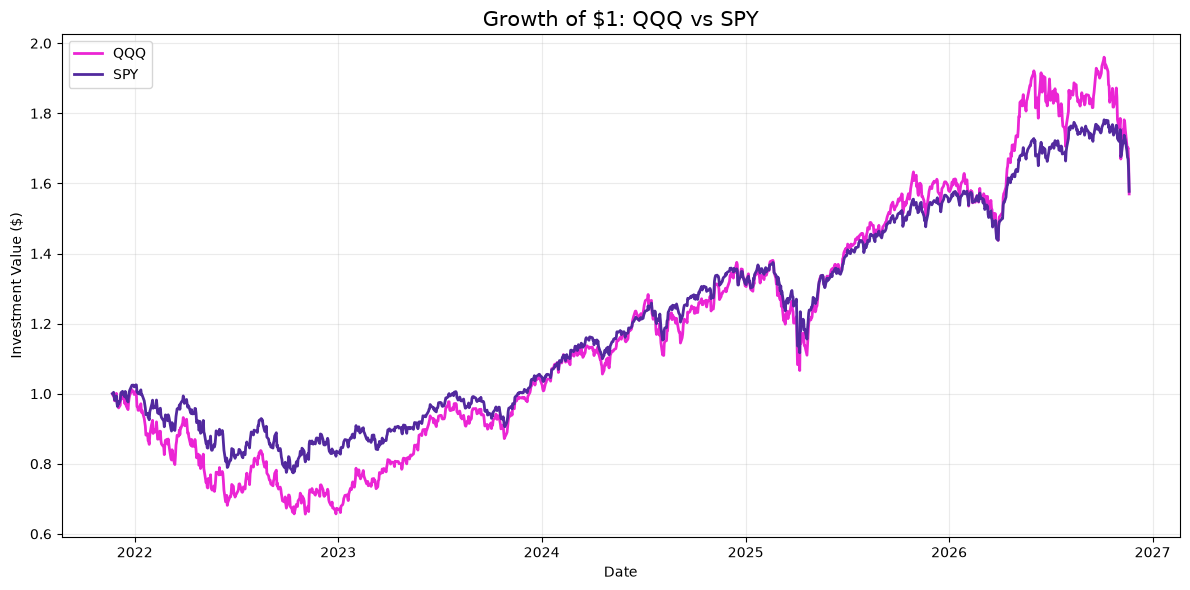

In [9]:
plt.figure(figsize=(12, 6))

plt.plot(
    growth.index,
    growth["QQQ"],
    label="QQQ",
    color="#EB25D4",
    linewidth=2
)

plt.plot(
    growth.index,
    growth["SPY"],
    label="SPY",
    color="#52299E",
    linewidth=2
)

plt.title("Growth of $1: QQQ vs SPY", fontsize=15)
plt.xlabel("Date")
plt.ylabel("Investment Value ($)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Drawdown analysis

A drawdown measures the percentage decline in cumulative portfolio value from its previous running peak.

**Formula**

`Drawdown (%) = ((Current Cumulative Growth / Previous Running Peak) - 1) × 100`

Where:

- **Current Cumulative Growth** is the cumulative growth value at time *t*.
- **Previous Running Peak** is the highest cumulative growth value observed up to and including time *t*.

**Maximum drawdown** is the most negative value in the drawdown series. It describes the largest peak-to-trough decline observed during the sample. It does not, by itself, show how long recovery took or whether the previous peak was eventually regained.

This measure provides a historical view of downside experience and complements the volatility analysis.


In [10]:
# Calculate the previous highest investment value
running_peak = growth.cummax()

# Calculate percentage drawdown
drawdowns = (growth / running_peak - 1) * 100

# Find maximum drawdown
maximum_drawdown = drawdowns.min()

print("Maximum Drawdown (%):")
print(maximum_drawdown.round(4))

Maximum Drawdown (%):
Ticker
QQQ   -35.1187
SPY   -24.4964
dtype: float64


### Drawdown findings

The maximum drawdowns in the saved sample are:

- **QQQ: -35.1187%**
- **SPY: -24.4964%**

QQQ experienced the deeper peak-to-trough decline. This is consistent with its higher measured volatility and indicates a larger historical maximum loss from a previous peak during this sample.

Maximum drawdown is period-dependent and describes the worst observed decline, not the loss an investor should expect in the future.


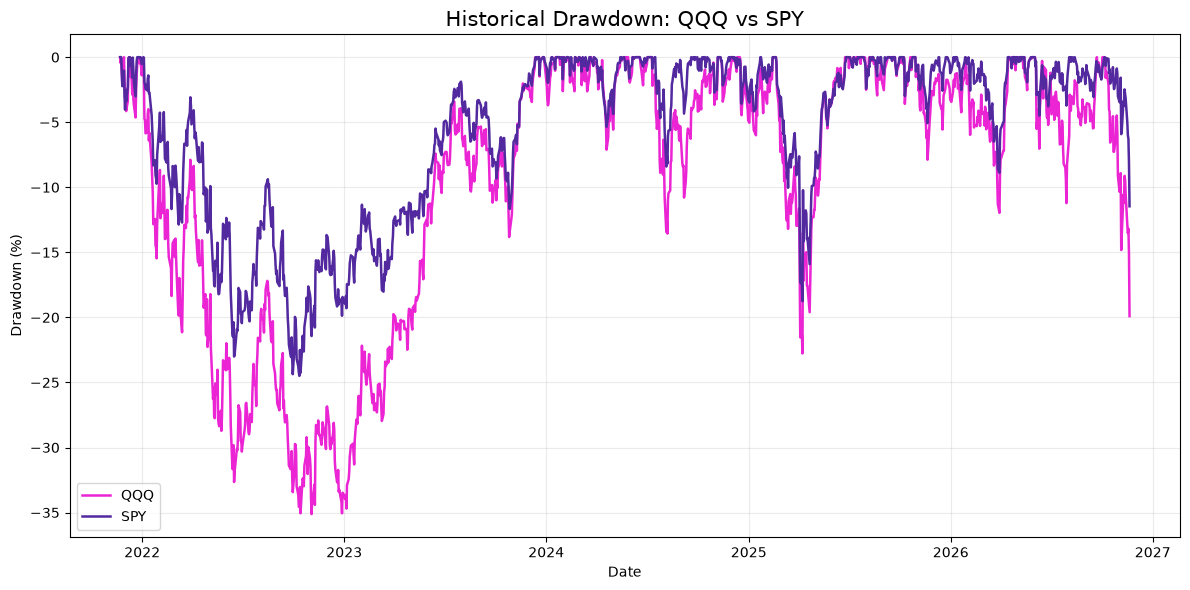

In [11]:
plt.figure(figsize=(12, 6))

plt.plot(
    drawdowns.index,
    drawdowns["QQQ"],
    label="QQQ",
    color="#EB25D4",
    linewidth=1.8
)

plt.plot(
    drawdowns.index,
    drawdowns["SPY"],
    label="SPY",
    color="#52299E",
    linewidth=1.8
)

plt.title("Historical Drawdown: QQQ vs SPY", fontsize=15)
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [12]:
print("Maximum Drawdown:")
print(drawdowns.min().round(4))

Maximum Drawdown:
Ticker
QQQ   -35.1187
SPY   -24.4964
dtype: float64


## 7. Risk-adjusted performance: Sharpe ratio

The Sharpe ratio measures average excess return per unit of return volatility. In this notebook, excess return is calculated relative to an assumed risk-free rate.

**Annualised formula**

`Sharpe Ratio = (Mean Daily Excess Return / Standard Deviation of Daily Returns) × √252`

**Methodology**

- The annual risk-free rate is assumed to be **0%**.
- The annual rate is converted to an equivalent daily rate.
- Daily excess returns are calculated by subtracting the daily risk-free rate from daily returns.
- The ratio is annualised using the square root of 252.

**Saved sample results:** QQQ = **0.5110**; SPY = **0.6197**.

**Interpretation**

SPY had the higher full-period Sharpe ratio under the zero risk-free-rate assumption. In this sample, it generated a higher return relative to its measured volatility according to this metric.

The zero risk-free rate is a simplifying assumption, not a historical estimate of Treasury yields. The result may change if a time-varying risk-free rate is used.


In [13]:

# Define the annual risk-free rate
risk_free_rate = 0.00

# Convert daily percentage returns into decimal returns
daily_returns_decimal = daily_returns / 100

# Convert the annual risk-free rate into an equivalent daily rate
daily_risk_free_rate = (1 + risk_free_rate) ** (1 / 252) - 1

# Calculate daily excess returns
daily_excess_returns = daily_returns_decimal - daily_risk_free_rate

# Calculate annualised Sharpe Ratio
sharpe_ratio = (
    daily_excess_returns.mean()
    / daily_returns_decimal.std()
) * np.sqrt(252)

# Display results
print("Annualised Sharpe Ratio:")
print(sharpe_ratio.round(4))


Annualised Sharpe Ratio:
Ticker
QQQ    0.5026
SPY    0.6117
dtype: float64


## 8. Downside risk: Sortino ratio

The Sortino ratio is a risk-adjusted performance measure similar to the Sharpe ratio, but it focuses on downside variability rather than total return volatility.

In this notebook, the **minimum acceptable return (MAR) is 0% per day**. Returns above this target do not contribute to downside deviation. The downside deviation is calculated from the squared shortfalls below the target, and the ratio is annualised using the 252-trading-day convention.

**Saved sample results:** QQQ = **0.7276**; SPY = **0.8905**.

SPY has the higher Sortino ratio in the saved sample, indicating stronger return relative to downside deviation under the selected zero-return target. The choice of target and annualisation convention affects the result.


In [14]:

# Calculate downside deviation using a 0% daily target
downside_returns = daily_excess_returns.clip(upper=0)

downside_deviation = np.sqrt(
    (downside_returns ** 2).mean()
)

# Calculate annualised Sortino Ratio
sortino_ratio = (
    daily_excess_returns.mean()
    / downside_deviation
) * np.sqrt(252)

print("Annualised Sortino Ratio:")
print(sortino_ratio.round(4))


Annualised Sortino Ratio:
Ticker
QQQ    0.7144
SPY    0.8776
dtype: float64


## 9. Rolling risk-adjusted performance

A rolling **252-trading-day Sharpe ratio** is calculated to examine how risk-adjusted performance changes over time. Each value uses the trailing 252 daily observations, representing approximately one trading year.

The initial part of the rolling series is unavailable until a complete window has accumulated.

**Latest saved observation (20 November 2026):**

- **QQQ:** 0.2384
- **SPY:** 0.4753

The rolling chart helps show whether the full-period comparison is consistent over time or whether relative performance changes across market conditions. A rolling ratio is sensitive to the observations entering and leaving each window.


In [15]:

# Define the rolling window (one trading year)
rolling_window = 252

# Calculate rolling annualised Sharpe Ratio
rolling_sharpe = (
    daily_excess_returns.rolling(window=rolling_window).mean()
    /
    daily_excess_returns.rolling(window=rolling_window).std()
) * np.sqrt(252)

# Display the latest rolling Sharpe Ratio
print("Latest Rolling 252-Day Sharpe Ratio:")
print(rolling_sharpe.iloc[-1].round(4))


Latest Rolling 252-Day Sharpe Ratio:
Ticker
QQQ    0.1966
SPY    0.4267
Name: 2026-11-20 00:00:00, dtype: float64


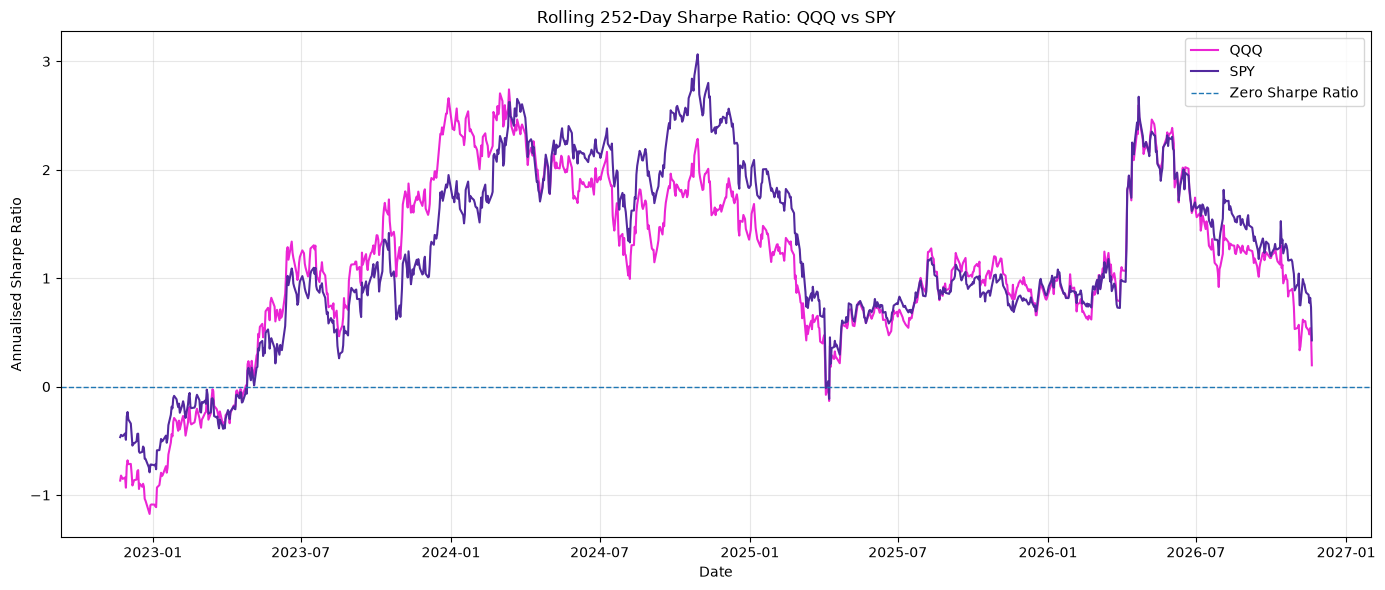

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    rolling_sharpe.index,
    rolling_sharpe["QQQ"],
    color="#EB25D4",
    label="QQQ",
    linewidth=1.5
)

plt.plot(
    rolling_sharpe.index,
    rolling_sharpe["SPY"],
    color="#52299E",
    label="SPY",
    linewidth=1.5
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1,
    label="Zero Sharpe Ratio"
)

plt.title("Rolling 252-Day Sharpe Ratio: QQQ vs SPY")
plt.xlabel("Date")
plt.ylabel("Annualised Sharpe Ratio")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 10. Rolling annualised volatility

Rolling annualised volatility measures how the variability of daily returns changes over time. This notebook uses a trailing window of 252 trading days.

**Formula**

`Rolling Annualised Volatility = Standard Deviation of the Previous 252 Daily Returns × √252`

**Methodology**

1. Calculate the standard deviation of daily returns within each 252-day window.
2. Annualise the result using the square root of 252.
3. Move the window forward one trading day and repeat the calculation.

The chart compares the rolling annualised volatility of QQQ and SPY. It helps identify periods of changing market variability and shows whether one ETF was consistently more volatile than the other.

**Latest saved observation (20 November 2026):**

- **QQQ:** 22.2023%
- **SPY:** 14.2033%

These are trailing one-year estimates, not forecasts of future volatility.


In [17]:

# Calculate rolling 252-day annualised volatility
rolling_volatility = (
    daily_returns.rolling(window=252).std()
) * np.sqrt(252)

# Display the latest rolling annualised volatility
print("Latest Rolling 252-Day Annualised Volatility:")
print(rolling_volatility.iloc[-1].round(4))


Latest Rolling 252-Day Annualised Volatility:
Ticker
QQQ    22.4118
SPY    14.3511
Name: 2026-11-20 00:00:00, dtype: float64


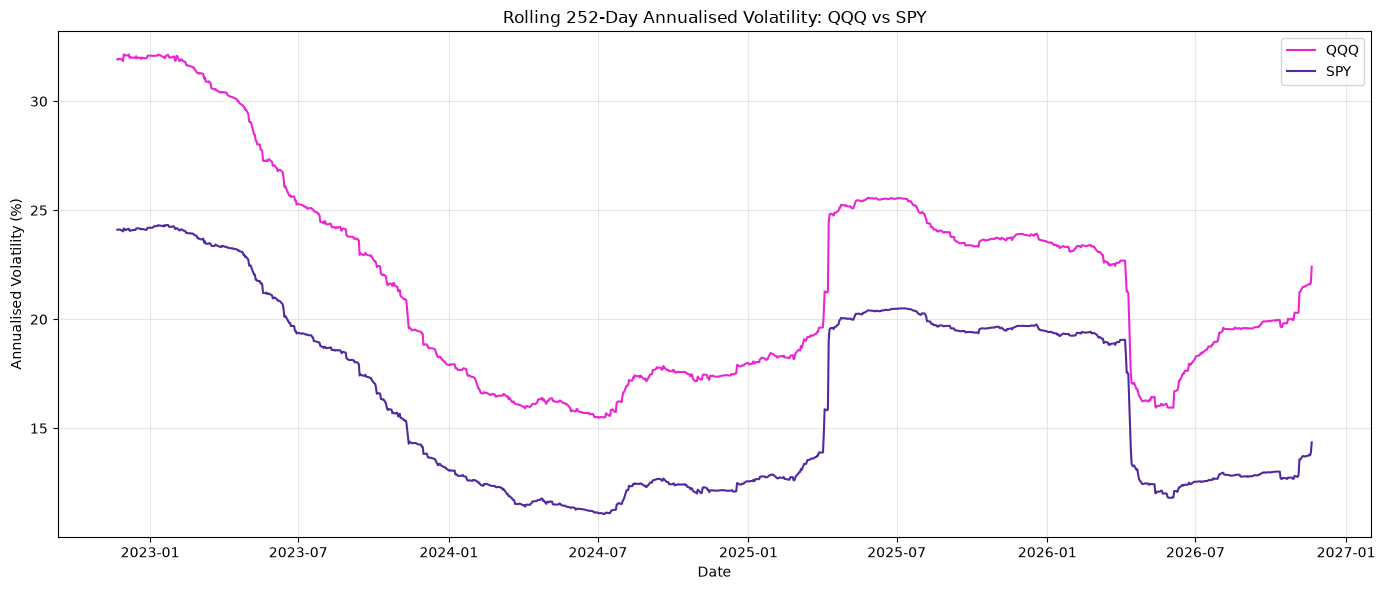

In [18]:

plt.figure(figsize=(14, 6))

plt.plot(
    rolling_volatility.index,
    rolling_volatility["QQQ"],
    color="#EB25D4",
    label="QQQ",
    linewidth=1.5
)

plt.plot(
    rolling_volatility.index,
    rolling_volatility["SPY"],
    color="#52299E",
    label="SPY",
    linewidth=1.5
)

plt.title("Rolling 252-Day Annualised Volatility: QQQ vs SPY")
plt.xlabel("Date")
plt.ylabel("Annualised Volatility (%)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:

# Identify the largest daily changes in rolling volatility
volatility_changes = rolling_volatility.diff()

for ticker in ["QQQ", "SPY"]:
    print(f"\nLargest rolling volatility changes: {ticker}")
    print(
        volatility_changes[ticker]
        .abs()
        .nlargest(5)
        .round(4)
    )

# Identify the largest absolute daily returns
for ticker in ["QQQ", "SPY"]:
    print(f"\nLargest daily returns: {ticker}")
    print(
        daily_returns[ticker]
        .abs()
        .nlargest(5)
        .round(4)
    )



Largest rolling volatility changes: QQQ
Date
2026-04-13    3.6250
2025-04-09    3.1592
2023-11-13    1.2953
2025-04-04    0.9313
2026-11-05    0.9259
Name: QQQ, dtype: float64

Largest rolling volatility changes: SPY
Date
2026-04-13    3.4105
2025-04-09    3.1648
2025-04-04    1.1280
2023-11-13    1.0003
2025-04-03    0.8467
Name: SPY, dtype: float64

Largest daily returns: QQQ
Date
2025-04-09    12.0031
2022-11-10     7.3788
2026-11-05     6.4889
2025-04-04     6.2109
2026-11-20     5.6725
Name: QQQ, dtype: float64

Largest daily returns: SPY
Date
2025-04-09    10.5019
2025-04-04     5.8543
2022-11-10     5.4954
2025-04-03     4.9281
2026-11-05     4.4092
Name: SPY, dtype: float64


## 11. Event-window inspection

The diagnostic cells identify dates with large changes in rolling volatility and large absolute daily returns. The final cell displays daily returns, rolling volatility and the one-day change in rolling volatility around a selected set of dates.

This provides context for interpreting the rolling-volatility series. A rolling estimate can change sharply when an unusually large return enters or leaves the 252-day window; therefore, a change in rolling volatility is not necessarily explained only by the return recorded on that date.

The event-window output is descriptive. It does not identify the economic or news-related cause of a market movement. Any causal or event-based explanation would require a separate analysis supported by reliable historical sources.


In [20]:

# Dates with the largest rolling volatility changes
event_dates = [
    "2026-04-13",
    "2025-04-09",
    "2023-11-13",
    "2025-04-04",
    "2026-11-05"
]

event_dates = pd.to_datetime(event_dates)

# Compare daily returns and rolling volatility
diagnostic = pd.concat(
    {
        "Daily Return (%)": daily_returns,
        "Rolling Volatility (%)": rolling_volatility,
        "Volatility Change (pp)": rolling_volatility.diff()
    },
    axis=1
)

# Display observations around each event date
for date in event_dates:
    print(f"\n{'='*55}")
    print(f"Event date: {date.date()}")
    print(diagnostic.loc[
        date - pd.Timedelta(days=1):
        date + pd.Timedelta(days=1)
    ].round(4))



Event date: 2026-04-13
           Daily Return (%)         Rolling Volatility (%)           \
Ticker                  QQQ     SPY                    QQQ      SPY   
Date                                                                  
2026-04-13           1.0343  0.9772                17.5607  14.0624   
2026-04-14           1.8157  1.2185                17.0857  13.3696   

           Volatility Change (pp)          
Ticker                        QQQ     SPY  
Date                                       
2026-04-13                 -3.625 -3.4105  
2026-04-14                 -0.475 -0.6928  

Event date: 2025-04-09
           Daily Return (%)          Rolling Volatility (%)           \
Ticker                  QQQ      SPY                    QQQ      SPY   
Date                                                                   
2025-04-08          -1.8008  -1.5663                21.2654  15.8659   
2025-04-09          12.0031  10.5019                24.4246  19.0308   
2025-04-10      

## 12. Overall findings and conclusion

### Main findings

1. **Average daily return:** QQQ recorded the higher average daily return (**0.0477%**) compared with SPY (**0.0429%**).
2. **Volatility:** QQQ was more volatile, with annualised volatility of **23.5089%**, compared with **17.4388%** for SPY.
3. **Maximum drawdown:** QQQ experienced the deeper maximum drawdown (**-35.1187%**) than SPY (**-24.4964%**).
4. **Full-period Sharpe ratio:** SPY recorded the higher ratio (**0.6197**) compared with QQQ (**0.5110**), using an assumed 0% annual risk-free rate.
5. **Full-period Sortino ratio:** SPY also recorded the higher ratio (**0.8905**) compared with QQQ (**0.7276**), using a 0% daily minimum acceptable return.
6. **Latest rolling Sharpe ratio:** on 20 November 2026, the trailing 252-day ratio was **0.4753 for SPY** and **0.2384 for QQQ**.
7. **Latest rolling annualised volatility:** on the same date, trailing volatility was **14.2033% for SPY** and **22.2023% for QQQ**.

### Conclusion

Across the five-year sample, **QQQ had the higher average daily return, while SPY had the stronger risk-adjusted results and the shallower maximum drawdown**. QQQ's higher average return was accompanied by greater overall volatility and a deeper historical peak-to-trough decline. The latest rolling measures also show higher volatility and a lower rolling Sharpe ratio for QQQ than for SPY.

The results illustrate the trade-off observed in this sample: QQQ delivered the higher average daily return, whereas SPY performed better on the selected risk-adjusted measures and experienced a smaller maximum drawdown. These findings are specific to the selected period and assumptions; they do not establish which ETF will perform better in the future or suit a particular investor.

### Limitations

- **Sample dependence:** Results depend on the selected five-year period and its start and end dates.
- **Risk-free rate:** The Sharpe ratio uses a constant 0% annual risk-free rate rather than historical Treasury yields.
- **Annualisation:** Volatility and risk-adjusted ratios use a 252-trading-day convention.
- **Simplified implementation:** Transaction costs, taxes, bid-ask spreads, tracking differences and investor-specific constraints are not included.
- **Data source:** Yahoo Finance is a third-party source. The downloaded observations have undergone basic validation, but have not been independently audited.
- **Descriptive event analysis:** The event-window inspection identifies dates and market movements but does not establish their causes.

### Possible extensions

Further work could include a time-varying risk-free rate, benchmark-relative measures such as beta and information ratio, sub-period comparisons, and out-of-sample analysis. These extensions would provide additional perspectives beyond the descriptive historical comparison in this notebook.
